# Step 5: Hidden-test dress rehearsal (Jian + Claude, Tue 17 Nov)
**Why:** the organisers will score our models on **held-out Madrid and Amsterdam pixels we have never seen** (Notebook 1, section 1.5). Our CV numbers come from pixels mixed in with the training pixels, which can be optimistic. This notebook copies the judges' situation as closely as we can:

1. Hide about 20% of each city as **whole neighbourhoods** (1.5 km blocks), straight from the RAW parquet files, before anything else happens.
2. Rebuild the whole frozen pipeline on the remaining 80% only: cleaning, features, Stage 1 Random Forest, Amsterdam own scaling, blend3 models for n = 5, 25, 50, 100, 200 (10 seeds each).
3. Give the hidden RAW rows to `predict.py`, exactly as the judges would, and score them.

**Leakage rules:** the hidden pixels never touch training, scaling, support sampling or any setting. Their labels are used only for the final score. Nothing in `models/` or `results/` from the official run is touched: everything goes into a new folder `rehearsal/`.

**Run time:** about 45 to 75 minutes (16 cores). Times are printed as it goes.

In [1]:
import time, json, importlib
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

import data_prep as dp, features_v3 as fv3, transfer_v3 as tv3, predict
for m in (dp, fv3, tv3, predict):
    importlib.reload(m)
assert hasattr(dp, "TEMPORAL_FACTOR") and hasattr(tv3, "smooth_proba"), "old modules loaded: upload the latest ones"

SEED, CLASSES = tv3.SEED, tv3.CLASSES
SHOTS  = (5, 25, 50, 100, 200)
TRIALS = 10                       # seeds 42..51, same as the official run
HOLDOUT_SHARE = 0.20              # share of 1.5 km blocks hidden per city
BLOCK = 50                        # 50 pixels x 30 m = 1.5 km, same blocks as our spatial CV
EVENTS = {"Madrid": 1960, "Amsterdam": 1945}

# find the raw files (works whether they sit in ./data or ../data)
for d in [Path("data"), Path("../data"), Path("../../data")]:
    if (d / "madrid_train.parquet").exists() and (d / "amsterdam_data.parquet").exists():
        DATA_DIR = d; break
else:
    raise FileNotFoundError("put the folder with madrid_train.parquet and amsterdam_data.parquet in DATA_DIR")
FILES = {"Madrid": DATA_DIR / "madrid_train.parquet", "Amsterdam": DATA_DIR / "amsterdam_data.parquet"}

R = Path("rehearsal"); (R / "models").mkdir(parents=True, exist_ok=True)
print("raw data in", DATA_DIR.resolve(), "| outputs in", R.resolve())

raw data in /home/participant-d1/Building_Age_Classification/data | outputs in /home/participant-d1/Building_Age_Classification/rehearsal


## 1. Hide whole neighbourhoods, then rebuild everything on the rest
Each pixel belongs to a 1.5 km block. 20% of the blocks of each city are chosen at random (seed 42) and hidden. Hidden raw rows are written to `rehearsal/hidden_<city>.parquet` and then forgotten until step 3.

In [2]:
t0 = time.time()
train_feat, hidden_path = {}, {}
for city, path in FILES.items():
    t = time.time()
    raw = dp.load_city(path)
    block = (raw["px_key"] // BLOCK).astype(np.int64) * 1_000_000 + (raw["py_key"] // BLOCK).astype(np.int64)
    blocks = np.unique(block)
    rng = np.random.default_rng(SEED)
    hide = rng.choice(blocks, int(round(HOLDOUT_SHARE * len(blocks))), replace=False)
    is_hidden = np.isin(block, hide)

    hidden_path[city] = R / f"hidden_{city.lower()}.parquet"
    raw[is_hidden].to_parquet(hidden_path[city], index=False)      # what the "judges" get
    train_raw = raw[~is_hidden]
    n_hid = raw.loc[is_hidden, ["px_key", "py_key"]].drop_duplicates().shape[0]
    n_tr = train_raw[["px_key", "py_key"]].drop_duplicates().shape[0]
    del raw

    # the frozen pipeline on the TRAINING part only (same calls as notebooks 01 and 02)
    clean = dp.add_age_class(dp.clean_long_table(train_raw, combine="median"), EVENTS[city])
    del train_raw
    feat, cols = fv3.build_features(clean)
    train_feat[city] = feat
    feat.to_parquet(R / f"train_features_{city.lower()}.parquet", index=False)
    print(f"{city}: {len(blocks)} blocks, {len(hide)} hidden | training pixels {n_tr:,}, hidden pixels {n_hid:,} "
          f"| classes in training {feat['age_class'].value_counts().sort_index().to_dict()}  ({time.time()-t:.0f}s)")

COLS = cols
assert COLS == json.load(open("feature_cols_v3.json")), "feature list differs from the official one"
print(f"step 1 done in {time.time()-t0:.0f}s")

temporal haze filter removed 27,363 photos (0.38% of clean photos)
built 61,731 pixels x 132 features (0 NaN values filled with the city median)
Madrid: 215 blocks, 43 hidden | training pixels 61,731, hidden pixels 14,532 | classes in training {1: 11385, 2: 21531, 3: 14861, 4: 13954}  (46s)
temporal haze filter removed 14,583 photos (0.74% of clean photos)
built 22,515 pixels x 132 features (0 NaN values filled with the city median)
Amsterdam: 112 blocks, 22 hidden | training pixels 22,515, hidden pixels 3,477 | classes in training {1: 6794, 2: 7668, 3: 5528, 4: 2525}  (21s)
step 1 done in 66s


## 2. Train the frozen method on the training part
Same as the official run: Stage 1 Random Forest on Madrid, Amsterdam scaled on its own (training) features, blend3 for every n and seed. Models are saved in the official format so `predict.py` can load them.

In [3]:
t0 = time.time()
m, a = train_feat["Madrid"], train_feat["Amsterdam"]
data = {"cols": COLS,
        "Xm": m[COLS].to_numpy(float), "ym": m["age_class"].to_numpy(int),
        "Xa": a[COLS].to_numpy(float), "ya": a["age_class"].to_numpy(int),
        "ids_a": a[["px_key", "py_key"]].to_numpy()}
stage1 = tv3.train_stage1(data)
stage1_path = R / "models" / "stage1_madrid_model.joblib"
joblib.dump({"rf": stage1["rf"], "scaler_amsterdam": stage1["scaler_a"], "feature_cols": COLS,
             "rf_params": tv3.RF_PARAMS, "scaling": tv3.SCALING}, stage1_path)
print(f"stage 1 trained and saved ({time.time()-t0:.0f}s)")

smallest = min((data["ya"] == c).sum() for c in CLASSES)
shots = [n for n in SHOTS if n <= smallest]
if len(shots) < len(SHOTS):
    print(f"NOTE: smallest Amsterdam training class has {smallest} pixels, skipping n > {smallest}")

ams_models = {}                      # (n, seed) -> path
cv_in_train = []                     # F1 on the training-part query pixels (like our official CV)
for n in shots:
    t = time.time()
    for k in range(TRIALS):
        f1, model = tv3.adapt_to_amsterdam(data, stage1, n, SEED + k, "blend3")
        p = R / "models" / f"amsterdam_blend3_n{n:03d}_seed{SEED + k}.joblib"
        joblib.dump(model, p)
        ams_models[(n, SEED + k)] = p
        cv_in_train.append({"n_per_class": n, "seed": SEED + k, "f1_query_in_training_area": f1})
    print(f"n={n:3d}: {TRIALS} models saved ({time.time()-t:.0f}s)")
cv_in_train = pd.DataFrame(cv_in_train)

stage 1 trained and saved (17s)
n=  5: 10 models saved (87s)
n= 25: 10 models saved (87s)
n= 50: 10 models saved (85s)
n=100: 10 models saved (86s)
n=200: 10 models saved (88s)


## 3. The judges' view: predict the hidden neighbourhoods with `predict.py`
First a full end-to-end call of `predict.predict_city` on each hidden RAW file (exactly what the organisers would run, including the safety net for pixels with no clean photo). Then, to score all 50 Amsterdam models without re-cleaning the file 50 times, we build the hidden features once with the same functions and check that this shortcut gives the same score as `predict.py`.

In [4]:
t0 = time.time()
# --- 3a. Madrid hidden test, full predict.py path (Stage 1 model) ---
out_m = predict.predict_city(hidden_path["Madrid"], "Madrid", stage1_path=str(stage1_path))
out_m_s = predict.predict_city(hidden_path["Madrid"], "Madrid", stage1_path=str(stage1_path), smooth=True,
                               context_features=str(R / "train_features_madrid.parquet"))
f1_mad = f1_score(out_m.true_age_class, out_m.predicted_age_class, average="macro")
f1_mad_s = f1_score(out_m_s.true_age_class, out_m_s.predicted_age_class, average="macro")

# --- 3b. Amsterdam hidden test, full predict.py path for one model (n=25, seed 42) ---
ref_model = ams_models[(25, SEED)] if (25, SEED) in ams_models else ams_models[(shots[0], SEED)]
out_a = predict.predict_city(hidden_path["Amsterdam"], "Amsterdam", stage1_path=str(stage1_path),
                             amsterdam_model_path=str(ref_model))
f1_ref_predictpy = f1_score(out_a.true_age_class, out_a.predicted_age_class, average="macro")
print(f"predict.py end to end: Madrid {f1_mad:.4f} (smoothed {f1_mad_s:.4f}) | "
      f"Amsterdam {ref_model.name} {f1_ref_predictpy:.4f}  ({time.time()-t0:.0f}s)")

temporal haze filter removed 5,485 photos (0.33% of clean photos)
built 14,532 pixels x 132 features (0 NaN values filled with the city median)
Madrid: macro F1 on ALL 14,532 pixels = 0.5871
predicted 14,532 pixels; class counts: {1: 2139, 2: 6077, 3: 3694, 4: 2622}
temporal haze filter removed 5,485 photos (0.33% of clean photos)
built 14,532 pixels x 132 features (0 NaN values filled with the city median)
smoothing with 61,731 context pixels
Madrid: macro F1 on ALL 14,532 pixels = 0.6088
predicted 14,532 pixels; class counts: {1: 2108, 2: 6307, 3: 3594, 4: 2523}
temporal haze filter removed 930 photos (0.31% of clean photos)
built 3,477 pixels x 132 features (0 NaN values filled with the city median)
Amsterdam: macro F1 on ALL 3,477 pixels = 0.5953
predicted 3,477 pixels; class counts: {1: 949, 2: 1085, 3: 1013, 4: 430}
predict.py end to end: Madrid 0.5871 (smoothed 0.6088) | Amsterdam amsterdam_blend3_n025_seed42.joblib 0.5953  (25s)


In [5]:
t0 = time.time()
# --- 3c. Hidden Amsterdam features once (same functions as predict.py) ---
raw_h = dp.load_city(hidden_path["Amsterdam"])
hid = fv3.build_features(dp.add_age_class(dp.clean_long_table(raw_h, combine="median"), EVENTS["Amsterdam"]))[0]
n_all = raw_h[["px_key", "py_key"]].drop_duplicates().shape[0]
del raw_h
Xh, yh, ids_h = hid[COLS].to_numpy(float), hid["age_class"].to_numpy(int), hid[["px_key", "py_key"]].to_numpy(np.int64)
print(f"hidden Amsterdam: {len(hid):,} of {n_all:,} pixels have features "
      f"({n_all - len(hid)} handled only by predict.py's safety net)")

# context for smoothing = the Amsterdam TRAINING pixels (as predict.py does with our transfer data)
Xc, ids_c = data["Xa"], data["ids_a"].astype(np.int64)
s1 = {"rf": stage1["rf"], "scaler_a": stage1["scaler_a"]}

# shortcut check: must equal predict.py's score for the reference model
P = tv3.predict_proba_blend3(joblib.load(ref_model), s1, Xh)
f1_ref_shortcut = f1_score(yh, CLASSES[P.argmax(1)], average="macro")
print(f"shortcut {f1_ref_shortcut:.4f} vs predict.py {f1_ref_predictpy:.4f}")
if n_all == len(hid):
    assert abs(f1_ref_shortcut - f1_ref_predictpy) < 1e-9, "shortcut differs from predict.py"

rows = []
for (n, seed), p in ams_models.items():
    model = joblib.load(p)
    P_h = tv3.predict_proba_blend3(model, s1, Xh)
    P_c = tv3.predict_proba_blend3(model, s1, Xc)
    P_s = tv3.smooth_proba(np.vstack([P_h, P_c]), np.vstack([ids_h, ids_c]), alpha=0.5)[: len(P_h)]
    rows.append({"n_per_class": n, "seed": seed,
                 "f1_hidden": f1_score(yh, CLASSES[P_h.argmax(1)], average="macro"),
                 "f1_hidden_smoothed": f1_score(yh, CLASSES[P_s.argmax(1)], average="macro")})
hidden = pd.DataFrame(rows).merge(cv_in_train, on=["n_per_class", "seed"])
print(f"scored {len(hidden)} Amsterdam models on the hidden neighbourhoods ({time.time()-t0:.0f}s)")

temporal haze filter removed 930 photos (0.31% of clean photos)
built 3,477 pixels x 132 features (0 NaN values filled with the city median)
hidden Amsterdam: 3,477 of 3,477 pixels have features (0 handled only by predict.py's safety net)
shortcut 0.5953 vs predict.py 0.5953
scored 50 Amsterdam models on the hidden neighbourhoods (50s)


## 4. Results: what the judges would probably see
Columns:
* **official CV**: our published numbers (all data, random split, section 7d of the log).
* **rehearsal, training area**: the same kind of score, but with models trained on 80% of the city (shows the cost of less data).
* **rehearsal, hidden neighbourhoods**: the judges' situation. The gap between the last two is the honest "unseen place" penalty, which also contains any optimism from our tuning choices.

,n_per_class,official_cv,train_area,hidden,hidden_std,hidden_smoothed,hidden_smoothed_std,smoothing_wins
0,5,0.580,0.5755,0.5106,0.0383,0.5161,0.0430,8
1,25,0.641,0.6461,0.5742,0.0297,0.5868,0.0303,10
2,50,0.666,0.6768,0.6018,0.0169,0.6203,0.0190,10
3,100,0.683,0.6933,0.6219,0.0107,0.6377,0.0103,10
4,200,0.703,0.7111,0.6284,0.0060,0.6444,0.0057,10


Madrid Stage 1: official random CV 0.656, spatial CV 0.616 | hidden neighbourhoods 0.5871, smoothed 0.6088
Amsterdam average of 5 n: official 0.655 | hidden 0.5874, smoothed 0.6011


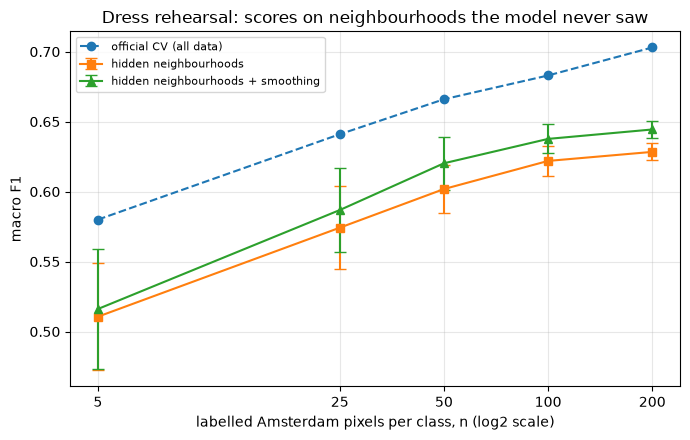

saved rehearsal/dress_rehearsal_*.csv and rehearsal/dress_rehearsal.png


In [6]:
OFFICIAL = {5: 0.580, 25: 0.641, 50: 0.666, 100: 0.683, 200: 0.703}     # section 7d
summary = (hidden.groupby("n_per_class")
           .agg(train_area=("f1_query_in_training_area", "mean"),
                hidden=("f1_hidden", "mean"), hidden_std=("f1_hidden", "std"),
                hidden_smoothed=("f1_hidden_smoothed", "mean"), hidden_smoothed_std=("f1_hidden_smoothed", "std"))
           .reset_index())
summary.insert(1, "official_cv", summary["n_per_class"].map(OFFICIAL))
summary["smoothing_wins"] = hidden.assign(w=hidden.f1_hidden_smoothed > hidden.f1_hidden).groupby("n_per_class")["w"].sum().values
display(summary.round(4))

print(f"Madrid Stage 1: official random CV 0.656, spatial CV 0.616 | hidden neighbourhoods {f1_mad:.4f}, smoothed {f1_mad_s:.4f}")
print(f"Amsterdam average of 5 n: official 0.655 | hidden {summary['hidden'].mean():.4f}, "
      f"smoothed {summary['hidden_smoothed'].mean():.4f}")

summary.round(4).to_csv(R / "dress_rehearsal_amsterdam.csv", index=False)
hidden.round(4).to_csv(R / "dress_rehearsal_all_runs.csv", index=False)
pd.DataFrame([{"city": "Madrid", "official_random_cv": 0.656, "official_spatial_cv": 0.616,
               "hidden": f1_mad, "hidden_smoothed": f1_mad_s}]).round(4).to_csv(R / "dress_rehearsal_madrid.csv", index=False)

x = np.log2(summary["n_per_class"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, summary["official_cv"], "o--", label="official CV (all data)")
ax.errorbar(x, summary["hidden"], yerr=summary["hidden_std"], fmt="s-", capsize=4, label="hidden neighbourhoods")
ax.errorbar(x, summary["hidden_smoothed"], yerr=summary["hidden_smoothed_std"], fmt="^-", capsize=4,
            label="hidden neighbourhoods + smoothing")
ax.set_xticks(x, summary["n_per_class"].astype(str))
ax.set_xlabel("labelled Amsterdam pixels per class, n (log2 scale)"); ax.set_ylabel("macro F1")
ax.set_title("Dress rehearsal: scores on neighbourhoods the model never saw")
ax.legend(fontsize=8); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(R / "dress_rehearsal.png", dpi=150); plt.show()
print("saved rehearsal/dress_rehearsal_*.csv and rehearsal/dress_rehearsal.png")